In [6]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [1]:
#importo le libreirie necessarie
from pymongo import MongoClient
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re

In [2]:
#importo i dati dal database e creo il mio data_set locale
client = MongoClient('mongodb://localhost:27017')

db = client['Football_Data']

collection_game_events = db['game_events']

documents = collection_game_events.find()

game_events_df = pd.DataFrame(list(documents)).drop('_id', axis=1)
game_events_df

,game_event_id,date,game_id,minute,type,club_id,player_id,description,player_assist_id,player_in_id
0,2f41da30c471492e7d4a984951671677,2012-08-05,2211607,77,Cards,610,4425,"1. Yellow card , Mass confrontation",NaN,NaN
1,a72f7186d132775f234d3e2f7bc0ed5b,2012-08-05,2211607,77,Cards,383,33210,"1. Yellow card , Mass confrontation",NaN,NaN
2,b2d721eaed4692a5c59a92323689ef18,2012-08-05,2211607,3,Goals,383,36500,", Header, 1. Tournament Goal Assist: , Corner,...",56416.0,NaN
3,aef768899cedac0c9a650980219075a2,2012-08-05,2211607,53,Goals,383,36500,", Right-footed shot, 2. Tournament Goal Assist...",146258.0,NaN
4,5d6d9533023057b6619ecd145a038bbe,2012-08-05,2211607,74,Substitutions,383,36500,", Not reported",NaN,49499.0
...,...,...,...,...,...,...,...,...,...,...
666553,7f5a6b61ca858e0cd63a58c554b56bb7,2023-11-15,4228114,82,Substitutions,358,874064,", Tactical",NaN,965607.0
666554,5b93d1bc9e8bf42965682d491e1dd6c7,2023-11-15,4228114,44,Goals,46889,922572,", Penalty, 1. Tournament Goal",NaN,NaN
666555,d638b1e72f531c413487d413258a3130,2023-11-15,4228114,68,Substitutions,46889,922572,", Tactical",NaN,1200869.0
666556,0ff7774aa1383af83e40c435325463af,2023-11-15,4228114,68,Substitutions,46889,1200864,", Tactical",NaN,921121.0


In [3]:
#tramite la descrizione posso osservare che sono presenti eventi in minutaggi o errati o sconosciuti (-1).
#Il minutaggio massimo è corretto(45 min * 2 = 90 min, partita normale, + 15 min * 2 = 30 min, tempi supplementari).
#90 min + 30 min = 120 min
game_events_df.describe()

,date,game_id,minute,club_id,player_id,player_assist_id,player_in_id
count,666558,6.665580e+05,666558.000000,666558.000000,6.665580e+05,3.085700e+04,4.212490e+05
mean,2018-04-19 13:44:55.438956800,3.051644e+06,63.503254,4595.409720,2.010716e+05,1.301114e+05,2.429946e+05
min,2012-07-03 00:00:00,2.211607e+06,-1.000000,1.000000,1.000000e+01,1.000000e+01,1.000000e+01
25%,2014-11-23 00:00:00,2.483327e+06,51.000000,336.000000,5.714400e+04,3.134800e+04,7.422300e+04
50%,2018-04-28 00:00:00,3.047444e+06,68.000000,984.000000,1.403100e+05,6.044400e+04,1.884980e+05
75%,2021-08-26 00:00:00,3.589539e+06,80.000000,3026.000000,2.912000e+05,1.404460e+05,3.481990e+05
max,2023-11-30 00:00:00,4.228114e+06,120.000000,112755.000000,1.207623e+06,1.207623e+06,1.207623e+06
std,NaN,6.079955e+05,21.927700,10915.447142,1.878795e+05,1.752904e+05,2.082146e+05


In [4]:
game_events_df.columns

Index(['game_event_id', 'date', 'game_id', 'minute', 'type', 'club_id',
       'player_id', 'description', 'player_assist_id', 'player_in_id'],
      dtype='object')

In [5]:
#posso vedere che i tipi eventi sono 4: Cartellini, Goal, Sostituzioni, Rigori.
type=game_events_df['type'].dropna().drop_duplicates()
type

0                 Cards
2                 Goals
4         Substitutions
613529         Shootout
Name: type, dtype: object

In [6]:
#creo un primo sottoinsieme per analizzare i cartellini
df_cards=game_events_df[['date', 'game_id', 'minute', 'type','club_id', 'player_id', 'description']]
df_cards=df_cards[~df_cards['type'].isna()] #controllo che il tipo non sia nullo
df_cards=df_cards[~df_cards['player_id'].isna()] #controllo che l'id del giocatore sia conosciuto
df_cards=df_cards[df_cards['type']=='Cards']#controllo che il tipo sia quello usato per i cartellini
df_cards

,date,game_id,minute,type,club_id,player_id,description
0,2012-08-05,2211607,77,Cards,610,4425,"1. Yellow card , Mass confrontation"
1,2012-08-05,2211607,77,Cards,383,33210,"1. Yellow card , Mass confrontation"
6,2012-08-05,2211607,90,Cards,610,42710,1. Yellow card
8,2012-08-05,2211607,79,Cards,610,45509,1. Yellow card
12,2012-08-05,2211607,37,Cards,383,68864,1. Yellow card
...,...,...,...,...,...,...,...
666534,2023-11-14,4227999,72,Cards,31367,201570,"1. Yellow card , Dissent"
666536,2023-11-14,4227999,39,Cards,1252,369561,"1. Yellow card , Foul"
666538,2023-11-14,4227999,80,Cards,31367,744754,"1. Yellow card , Dissent"
666539,2023-11-15,4228114,43,Cards,358,129558,"1. Yellow card , Foul"


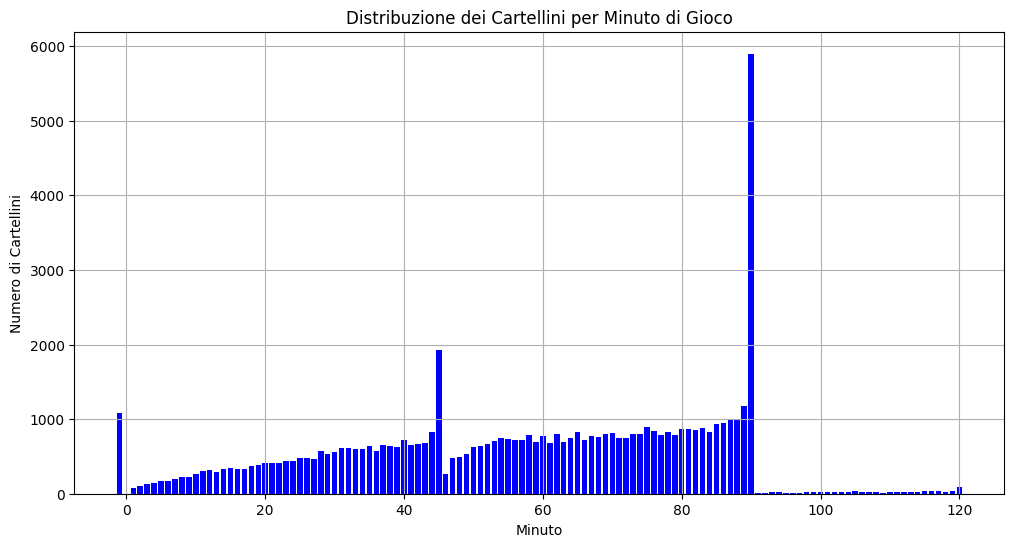

In [7]:
#Provo a vedere qual è il minutaggio in cui sono presenti più cartellini, senza stupore possiamo vedere che è al 90esimo
#sono inoltre presenti alcuni cartellini di cui non si conosce il minutaggio
cards_by_minute = df_cards.groupby('minute').size().reset_index(name='num_cards')

# Crea il grafico a barre
plt.figure(figsize=(12, 6))
plt.bar(cards_by_minute['minute'], cards_by_minute['num_cards'], color='blue')
plt.xlabel('Minuto')
plt.ylabel('Numero di Cartellini')
plt.title('Distribuzione dei Cartellini per Minuto di Gioco')
plt.grid(True)
plt.show()

In [8]:
#importo i dati necessari per identificre squadre e calciatori
club_df= pd.read_csv('clubs.csv')[['club_id','name']]

player_df= pd.read_csv('players.csv')[['player_id','name']]

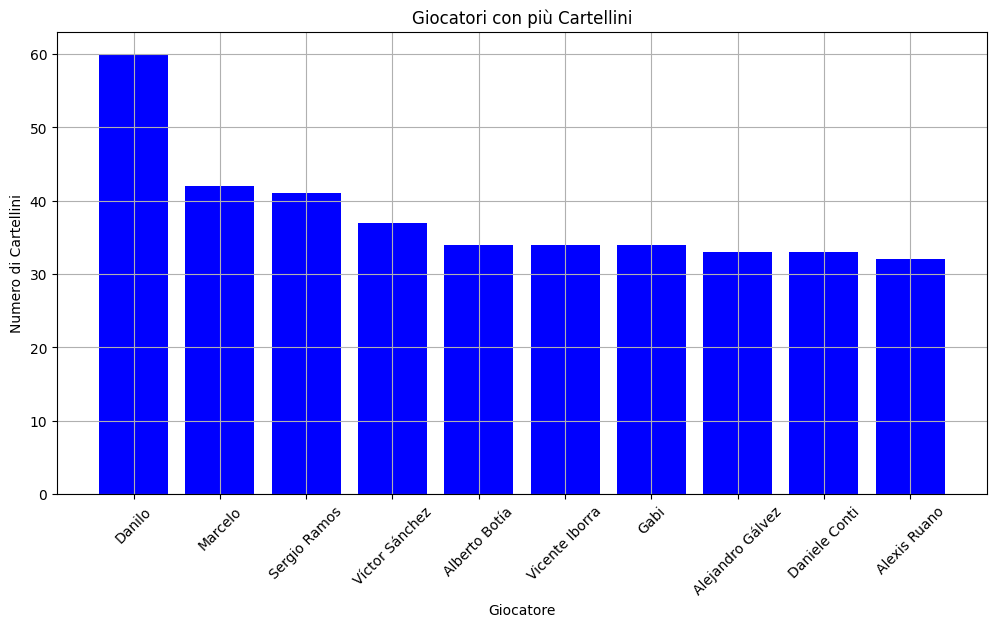

In [9]:
# Unisco df_cards con player_df per ottenere i nomi dei giocatori
player_cards = pd.merge(df_cards, player_df, how='left', on='player_id')
player_cards.rename(columns={'name': 'player_name'}, inplace=True)

# Raggruppo per player_id e conto il numero di cartellini per ogni giocatore
cards_by_player = player_cards.groupby('player_name').size().reset_index(name='num_cards').sort_values(by='num_cards', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(cards_by_player['player_name'], cards_by_player['num_cards'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Numero di Cartellini')
plt.title('Giocatori con più Cartellini')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

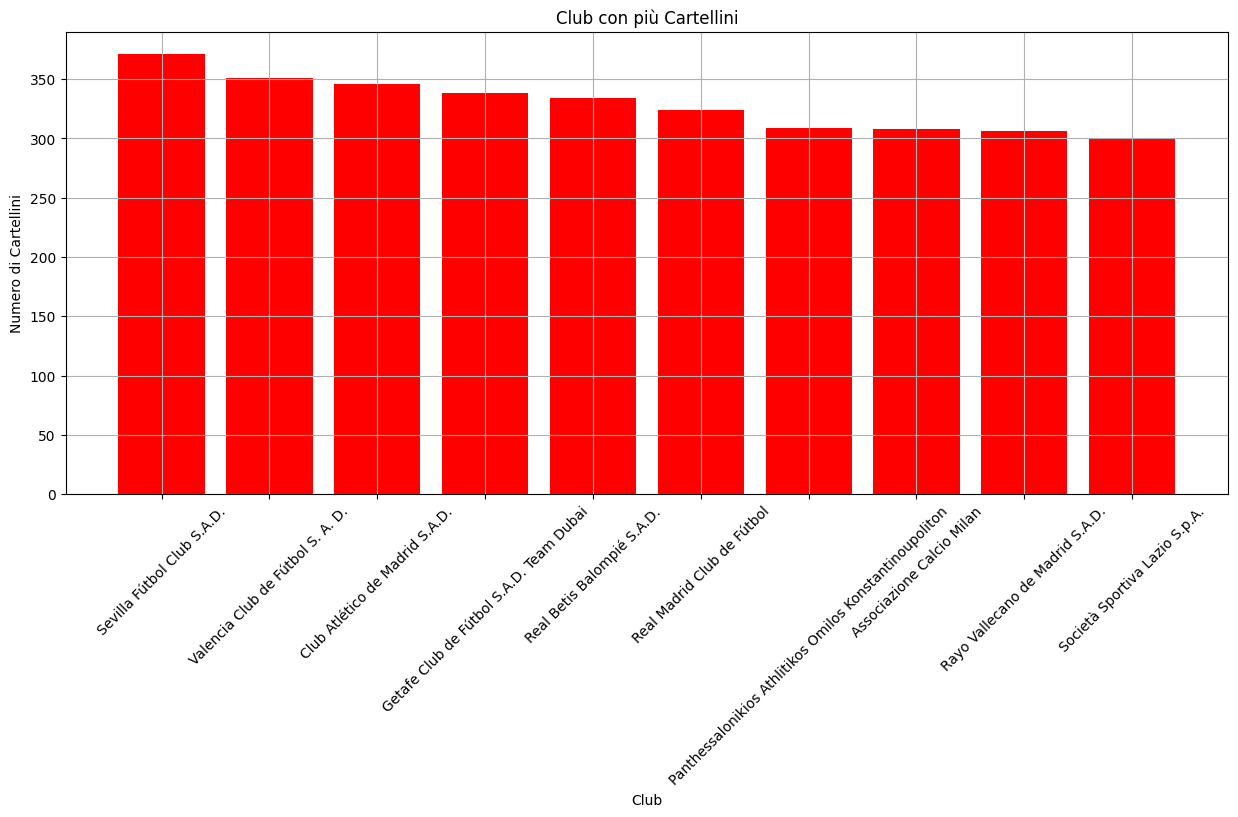

In [10]:
# Unisco df_cards con club_df per ottenere i nomi dei club
club_cards = pd.merge(df_cards, club_df, how='left', on='club_id')
club_cards.rename(columns={'name': 'club_name'}, inplace=True)

# Raggruppa per club_id e conta il numero di cartellini per ogni club
cards_by_club = club_cards.groupby('club_name').size().reset_index(name='num_cards').sort_values(by='num_cards', ascending=False).head(10)

plt.figure(figsize=(15, 6))
plt.bar(cards_by_club['club_name'], cards_by_club['num_cards'], color='red')
plt.xlabel('Club')
plt.ylabel('Numero di Cartellini')
plt.title('Club con più Cartellini')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [11]:
#ora creo un sottoinsieme per analizzare i goal, la descrizione non verrà usata perché troppo libera a interpretazioni
df_goals=game_events_df[['date', 'game_id', 'minute', 'type','club_id', 'player_id', 'player_assist_id']]
df_goals=df_goals[~df_goals['type'].isna()] #controllo che il tipo non sia nullo
df_goals=df_goals[~df_goals['player_id'].isna()] #controllo che l'id del giocatore sia conosciuto
df_goals=df_goals[df_goals['type']=='Goals']#controllo che il tipo sia quello usato per i goal
df_goals

,date,game_id,minute,type,club_id,player_id,player_assist_id
2,2012-08-05,2211607,3,Goals,383,36500,56416.0
3,2012-08-05,2211607,53,Goals,383,36500,146258.0
5,2012-08-05,2211607,11,Goals,383,38497,33210.0
7,2012-08-05,2211607,44,Goals,610,42710,4425.0
9,2012-08-05,2211607,90,Goals,383,49499,167850.0
...,...,...,...,...,...,...,...
666546,2023-11-15,4228114,51,Goals,358,479987,193079.0
666549,2023-11-15,4228114,77,Goals,358,747267,203127.0
666552,2023-11-15,4228114,49,Goals,358,874064,874062.0
666554,2023-11-15,4228114,44,Goals,46889,922572,NaN


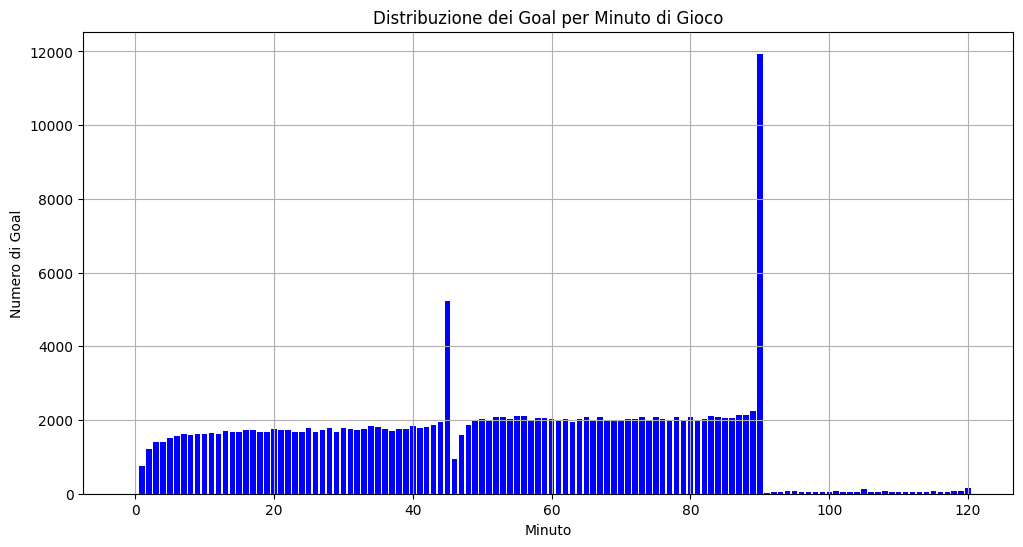

In [12]:
#Provo a vedere qual è il minutaggio in cui sono presenti più goal, intorno al 45esimo minuto i goal raddoppiano per poi raddoppiare
#ulteriormente intorno al 90esimo minuto
#una ipotesi percui al 45esimo e al 90esimo ci siano così tanti goal potrebbe essere che tutti i goal dei minuti supplementari vengano
#raccolti nel 45esimo e 90esimo. 
goals_by_minute = df_goals.groupby('minute').size().reset_index(name='num_goals')

plt.figure(figsize=(12, 6))
plt.bar(goals_by_minute['minute'], goals_by_minute['num_goals'], color='blue')
plt.xlabel('Minuto')
plt.ylabel('Numero di Goal')
plt.title('Distribuzione dei Goal per Minuto di Gioco')
plt.grid(True)
plt.show()

In [13]:
#ho provato a fare un analisi più approfondita ma le descrizioni come detto prima non sono di facile interpretazione

nov=game_events_df[['date', 'game_id', 'minute', 'type','club_id', 'player_id', 'player_assist_id', 'description']]
nov=nov[~nov['type'].isna()] #controllo che il tipo non sia nullo
nov=nov[~nov['player_id'].isna()] #controllo che l'id del giocatore sia conosciuto
nov=nov[nov['type']=='Goals']#controllo che il tipo sia quello usato per i goal
nov=nov[(nov['minute']==45)|(nov['minute']==90)]['description']
nov

9         , Right-footed shot, 1. Tournament Goal Assist...
59        , Left-footed shot, 3. Tournament Goal Assist:...
156       , Right-footed shot, 1. Tournament Goal Assist...
177       , Left-footed shot, 1. Tournament Goal Assist:...
192       , Right-footed shot, 1. Tournament Goal Assist...
                                ...                        
666245    , Penalty, 7. Goal of the Season Assist: Handb...
666251    , Header, 3. Goal of the Season Assist: , Pass...
666267    , Header, 1. Goal of the Season Assist: , Corn...
666485    , Header, 2. Tournament Goal Assist: , Corner,...
666513               , Left-footed shot, 1. Tournament Goal
Name: description, Length: 17169, dtype: object

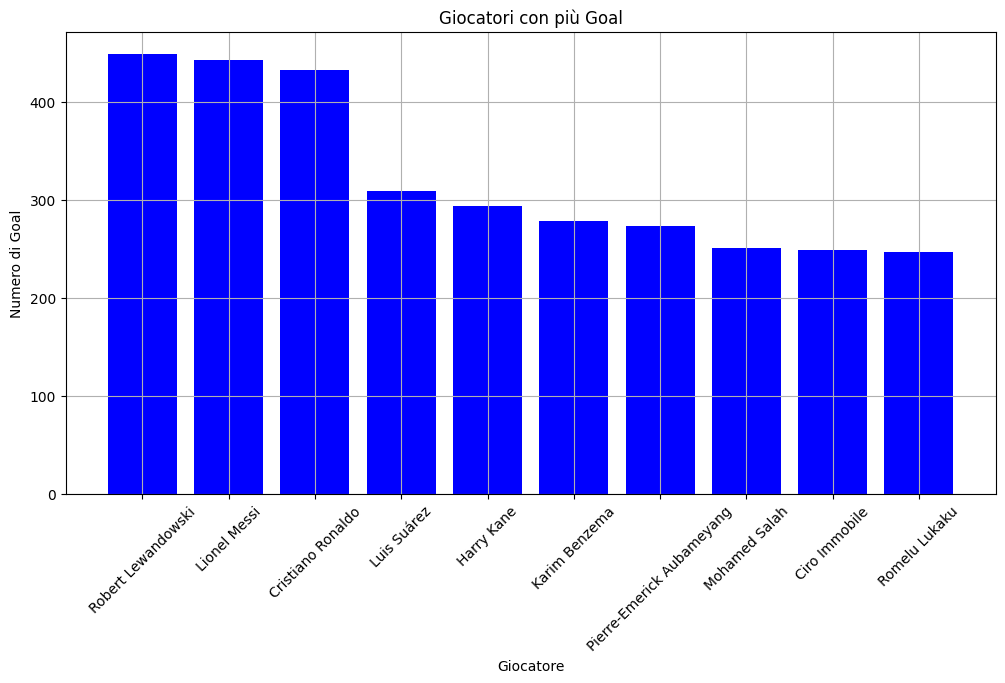

In [14]:
# Ora provo a vedere qual è il giocatore con più goal segnati
player_goals = pd.merge(df_goals, player_df, how='left', on='player_id')
player_goals.rename(columns={'name': 'player_name'}, inplace=True)

goals_by_player = player_goals.groupby('player_name').size().reset_index(name='num_goals').sort_values(by='num_goals', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(goals_by_player['player_name'], goals_by_player['num_goals'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Numero di Goal')
plt.title('Giocatori con più Goal')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

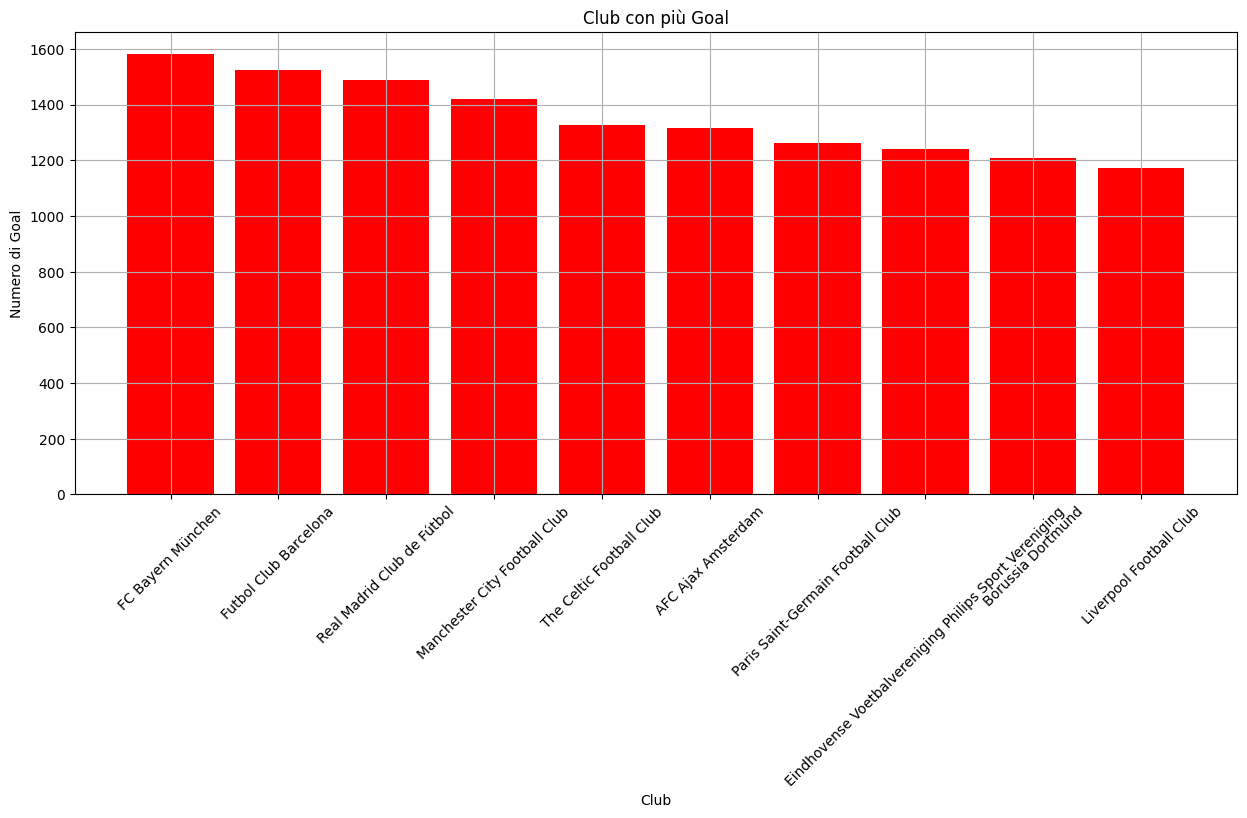

In [15]:
#qua invece analizzo quale sia il club con più goal segnati
club_goals = pd.merge(df_goals, club_df, how='left', on='club_id')
club_goals.rename(columns={'name': 'club_name'}, inplace=True)

goals_by_club = club_goals.groupby('club_name').size().reset_index(name='num_goals').sort_values(by='num_goals', ascending=False).head(10)

plt.figure(figsize=(15, 6))
plt.bar(goals_by_club['club_name'], goals_by_club['num_goals'], color='red')
plt.xlabel('Club')
plt.ylabel('Numero di Goal')
plt.title('Club con più Goal')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [16]:
#ora creo un sottoinsieme per analizzare le sostituzioni e quando queste tipicamente vengono fatte

df_substitution=game_events_df[['date', 'game_id', 'minute', 'type','club_id', 'player_id', 'player_in_id', 'description']]

df_substitution=df_substitution[~df_substitution['type'].isna()] #controllo che il tipo non sia nullo
df_substitution=df_substitution[(~df_substitution['player_id'].isna())] #controllo che l'id del giocatore sia conosciuto

df_substitution=df_substitution[df_substitution['type']=='Substitutions']#controllo che il tipo sia quello usato per i goal
df_substitution

,date,game_id,minute,type,club_id,player_id,player_in_id,description
4,2012-08-05,2211607,74,Substitutions,383,36500,49499.0,", Not reported"
10,2012-08-05,2211607,76,Substitutions,610,52246,182932.0,", Not reported"
13,2012-08-05,2211607,84,Substitutions,383,72462,167850.0,", Not reported"
14,2012-08-05,2211607,65,Substitutions,610,95755,34784.0,", Not reported"
17,2012-08-05,2211607,76,Substitutions,610,187245,111184.0,", Not reported"
...,...,...,...,...,...,...,...,...
666550,2023-11-15,4228114,59,Substitutions,46889,814815,550816.0,", Tactical"
666551,2023-11-15,4228114,63,Substitutions,46889,839808,1203716.0,", Injury"
666553,2023-11-15,4228114,82,Substitutions,358,874064,965607.0,", Tactical"
666555,2023-11-15,4228114,68,Substitutions,46889,922572,1200869.0,", Tactical"


In [17]:
type_substitution=df_substitution['description'].dropna().drop_duplicates()
type_substitution
#significati:
#'not reported': nan
#'tactical': scambio tattico per cambiare stile di gioco
#'delay':
#'resting': per far riposare un giocatore
#'injury': un giocatore si è infortunato
#'risk of booking': per evitare che un giocatore venga espulso
#'special achievements':sono segni distintivi che onorano le prestazioni e i contributi eccezionali nel mondo del calcio, possono essere motivo di
#sostituzione per un impatto psicologico sulla propria squadra o sulla squadra avversaria
#'Substitution without replacement': sostituzioni senza rimpiazio, esempio espulsioni o assenza di sostituti dopo un infortunio

4                            , Not reported
81                               , Tactical
101                                 , Delay
122                               , Resting
140                                , Injury
183                       , Risk of booking
186                  , Special achievements
16280    , Substitution without replacement
Name: description, dtype: object

In [19]:
cond1 = df_substitution['description'] == ', Substitution without replacement'
cond2 = df_substitution['player_in_id'].isna()

df_substitution = df_substitution[~(cond1 & ~cond2)]
df_substitution = df_substitution[~(~cond1 & cond2)]

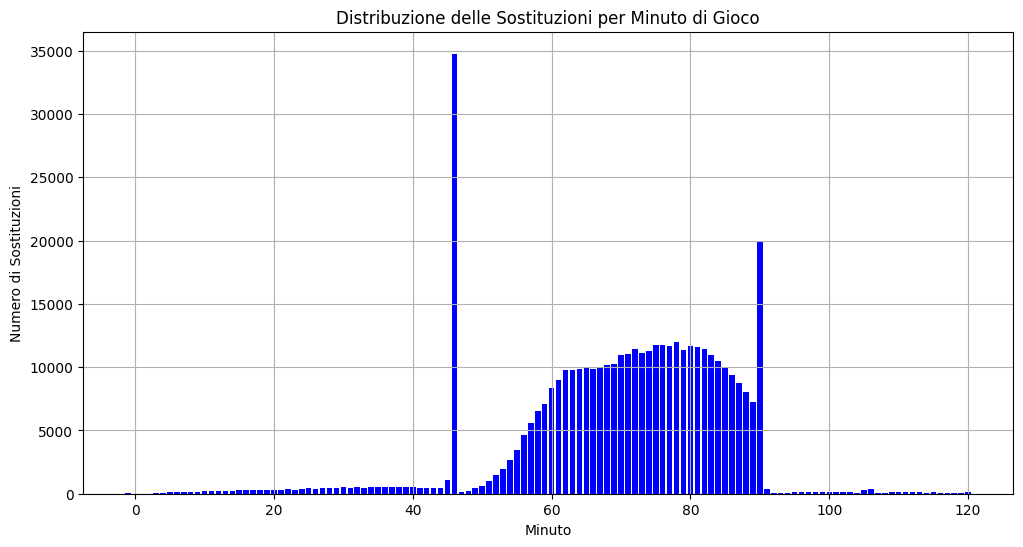

In [20]:
#Provo a vedere qual è il minutaggio in cui sono presenti più sostituzioni.
#la maggior parte delle sostituzioni avvengo al 45esimo, probabilmente dovuto all'intervallo, poi nel secondo tempo aumentano
#rispetto al primo tempo(possibile stanchezza) e intorno a 90esimo c'è il secondo picco, magari dovuto al tentativo di segnare
#al termine
substitutions_by_minute = df_substitution.groupby('minute').size().reset_index(name='num_substitution')

plt.figure(figsize=(12, 6))
plt.bar(substitutions_by_minute['minute'], substitutions_by_minute['num_substitution'], color='blue')
plt.xlabel('Minuto')
plt.ylabel('Numero di Sostituzioni')
plt.title('Distribuzione delle Sostituzioni per Minuto di Gioco')
plt.grid(True)
plt.show()

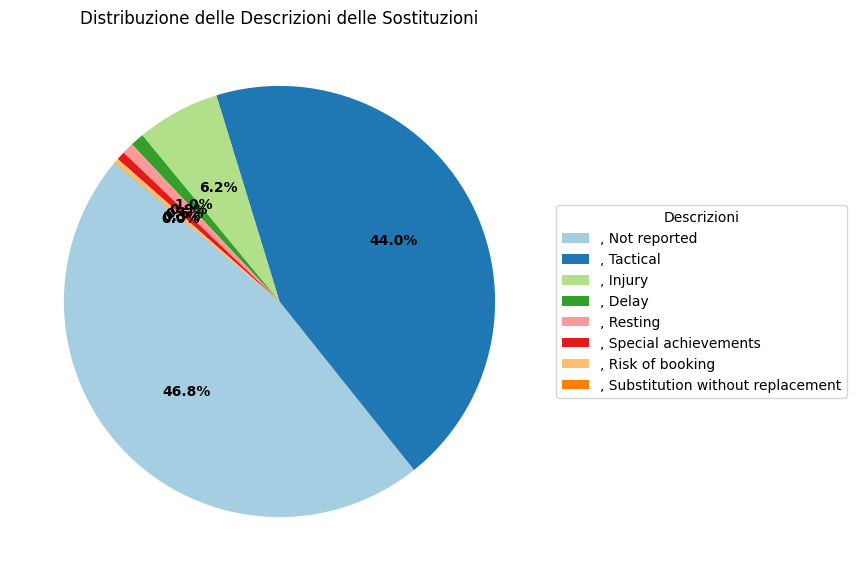

In [21]:
# voglio vedere quali sono le percentuali di tipo di sostituzione
description_counts = df_substitution['description'].value_counts()

fig, ax = plt.subplots(figsize=(10, 7))
wedges, texts, autotexts = ax.pie(description_counts, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired(range(len(description_counts))))

ax.legend(wedges, description_counts.index, title="Descrizioni", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.setp(autotexts, size=10, weight="bold")
ax.set_title('Distribuzione delle Descrizioni delle Sostituzioni')

plt.show()
#quasi il 50% dei motivi per la sostituzione non è riportato, quindi per chiarezza dell'analizi li rimuoviamo per
#analizzare meglio le restanti, per maggior leggibilità cambieremo il grafico usato.

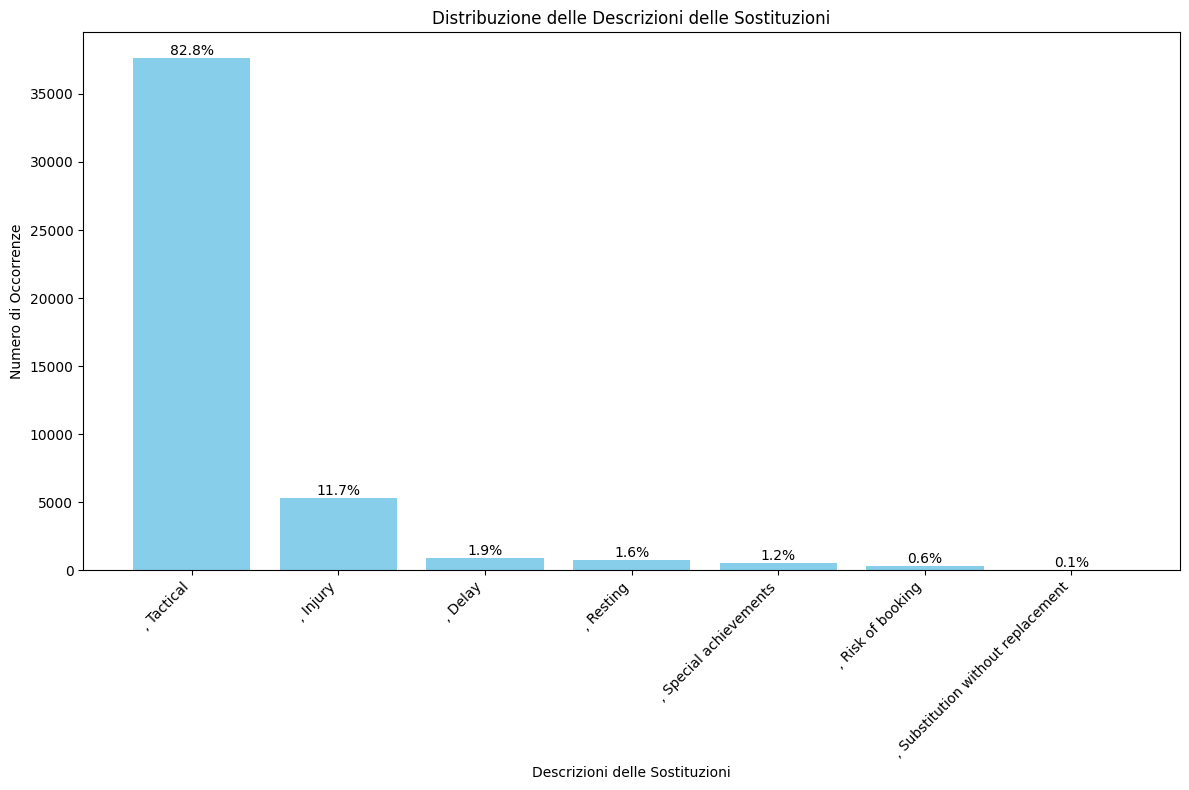

In [22]:
cond = df_substitution['description'] != ', Not reported'
df_substitution = df_substitution[cond]

description_counts = df_substitution['description'].value_counts()

total_count = description_counts.sum()
percentages = (description_counts / total_count) * 100

descriptions = description_counts.index
counts = description_counts.values

plt.figure(figsize=(12, 8))
bars = plt.bar(descriptions, counts, color='skyblue')

for bar, percentage in zip(bars, percentages):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{percentage:.1f}%', ha='center', va='bottom', fontsize=10, color='black')

plt.xlabel('Descrizioni delle Sostituzioni')
plt.ylabel('Numero di Occorrenze')
plt.title('Distribuzione delle Descrizioni delle Sostituzioni')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()
#Possiamo vedere che la quasi totalità delle ragioni di una sostituzione sta nel fare un cambio tattico, mentre solo l'0,1% delle sostituzioni
#sono senza rimpiazzo

In [23]:
#ora creo un sottoinsieme per analizzare i calci di rigore, e quali giocatori/club sono i migliori

df_shootouts=game_events_df[['date', 'game_id', 'minute', 'type','club_id', 'player_id', 'description']]
df_shootouts=df_shootouts[~df_shootouts['type'].isna()] #controllo che il tipo non sia nullo
df_shootouts=df_shootouts[~df_shootouts['player_id'].isna()] #controllo che l'id del giocatore sia conosciuto
df_shootouts=df_shootouts[df_shootouts['type']=='Shootout']#controllo che il tipo sia quello usato per i rigori
df_shootouts

,date,game_id,minute,type,club_id,player_id,description
613529,2023-01-11,3998376,-1,Shootout,418,18922,", Scored"
613530,2023-01-11,3998376,-1,Shootout,418,27992,", Scored"
613531,2023-01-11,3998376,-1,Shootout,418,31909,", Scored"
613533,2023-01-11,3998376,-1,Shootout,1049,48280,", Scored"
613536,2023-01-11,3998376,-1,Shootout,1049,221322,", Saved"
...,...,...,...,...,...,...,...
666515,2023-11-14,4227998,-1,Shootout,1072,485994,", Scored"
666518,2023-11-14,4227998,-1,Shootout,1072,552615,", Saved"
666521,2023-11-14,4227998,-1,Shootout,34888,583997,", Saved"
666524,2023-11-14,4227998,-1,Shootout,1072,701062,", Scored"


In [24]:
df_shootouts.describe()
#possiamo affermare che il minuto -1 è quello usato per rappresentare i rigori

,date,game_id,minute,club_id,player_id
count,1276,1.276000e+03,1276.0,1276.000000,1.276000e+03
mean,2023-08-30 11:17:06.959247616,4.148727e+06,-1.0,19404.622257,4.723447e+05
min,2023-01-11 00:00:00,3.998376e+06,-1.0,9.000000,8.187000e+03
25%,2023-08-08 00:00:00,4.126958e+06,-1.0,1072.000000,2.532185e+05
50%,2023-08-29 00:00:00,4.148218e+06,-1.0,4616.000000,4.295450e+05
75%,2023-09-20 00:00:00,4.168264e+06,-1.0,28098.000000,6.539760e+05
max,2023-11-25 00:00:00,4.227998e+06,-1.0,112611.000000,1.198332e+06
std,NaN,3.796027e+04,0.0,27997.816618,2.771456e+05


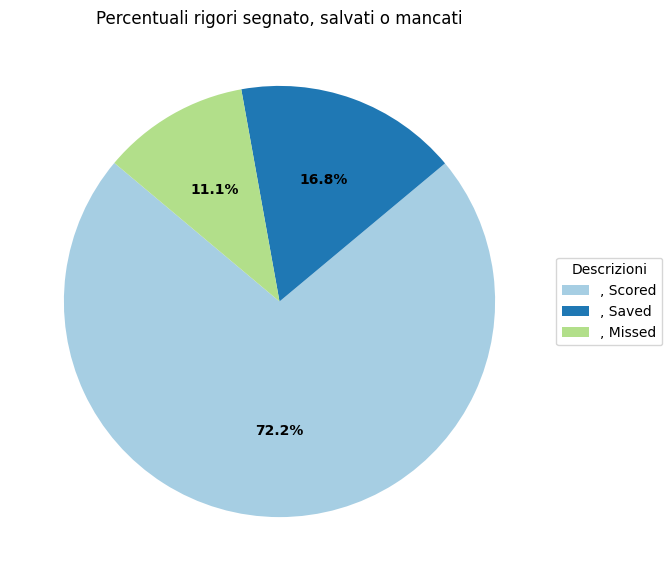

In [25]:
#Analizzo le percentuali di rigori andati a segno, parati oppure mancati. Da come si può osservare la maggiorparte dei
#rigori va in rete, mentre quelli che mancano la porta andando sul fondo sono la minoranza.

description_shootout_counts = df_shootouts['description'].value_counts()

fig, ax = plt.subplots(figsize=(10, 7))
wedges, texts, autotexts = ax.pie(description_shootout_counts, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired(range(len(description_counts))))

ax.legend(wedges, description_shootout_counts.index, title="Descrizioni", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.setp(autotexts, size=10, weight="bold")
ax.set_title('Percentuali rigori segnato, salvati o mancati')

plt.show()

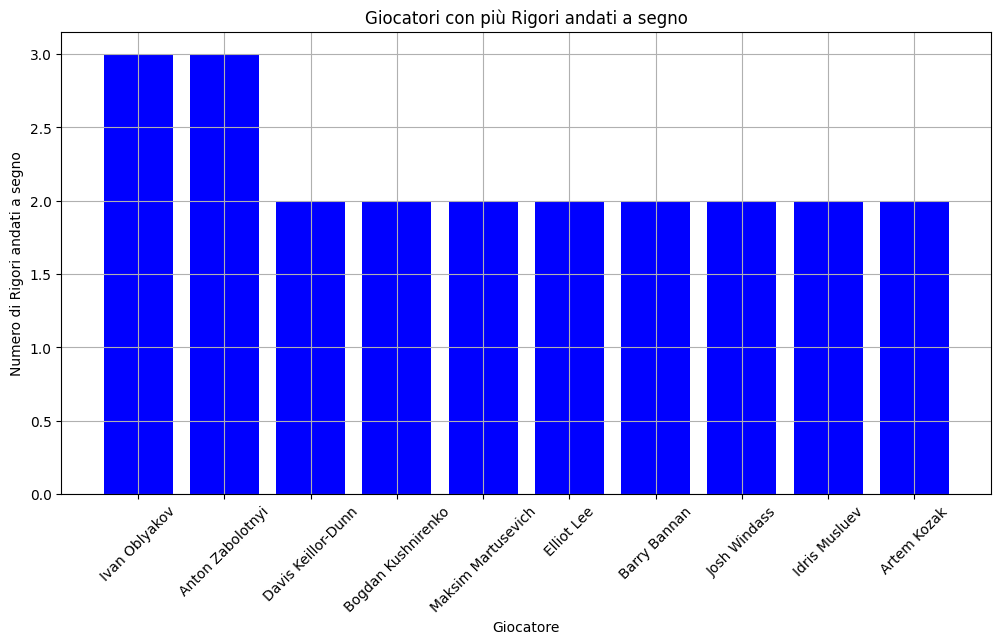

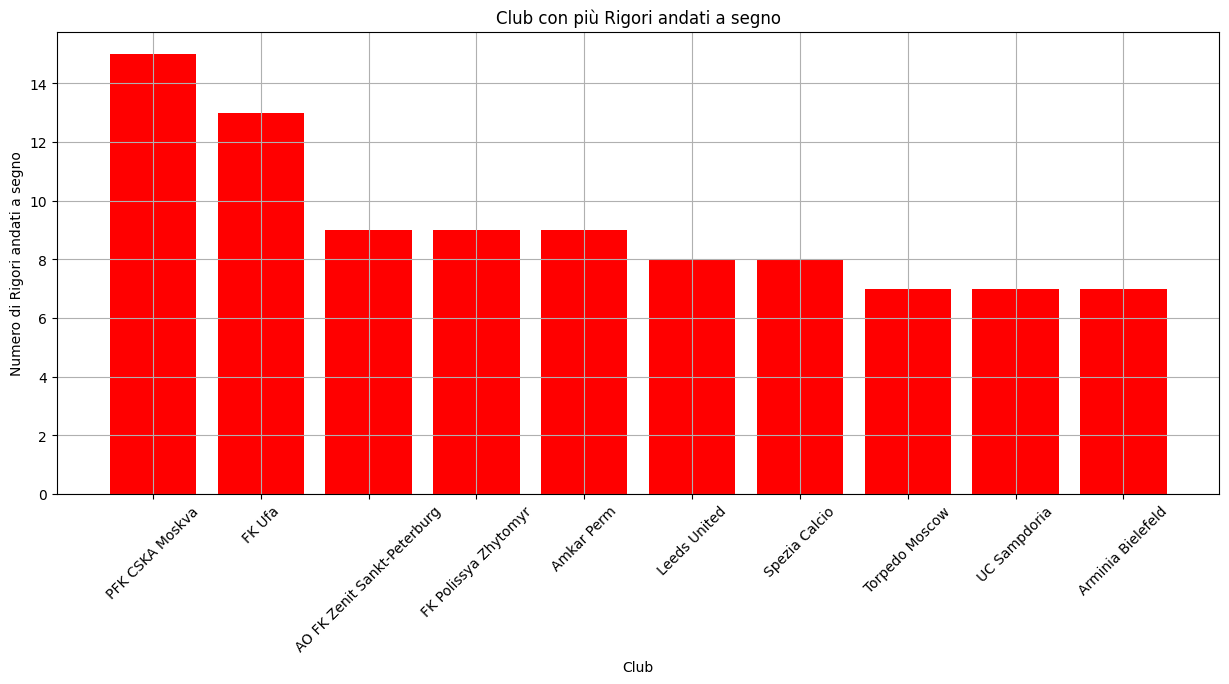

In [26]:
#adesso vado ad analizzare qual è il calciatore e il club con più rigori portati a segno

scored_shootout = df_shootouts[df_shootouts['description'] == ', Scored']
player_shootout = pd.merge(scored_shootout, player_df, how='left', on='player_id')
player_shootout.rename(columns={'name': 'player_name'}, inplace=True)

shootout_by_player = player_shootout.groupby('player_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i giocatori
plt.figure(figsize=(12, 6))
plt.bar(shootout_by_player['player_name'], shootout_by_player['num_shootout'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Numero di Rigori andati a segno')
plt.title('Giocatori con più Rigori andati a segno')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

club_shootout = pd.merge(scored_shootout, club_df, how='left', on='club_id')
club_shootout.rename(columns={'name': 'club_name'}, inplace=True)

shootout_by_club = club_shootout.groupby('club_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i club
plt.figure(figsize=(15, 6))
plt.bar(shootout_by_club['club_name'], shootout_by_club['num_shootout'], color='red')
plt.xlabel('Club')
plt.ylabel('Numero di Rigori andati a segno')
plt.title('Club con più Rigori andati a segno')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

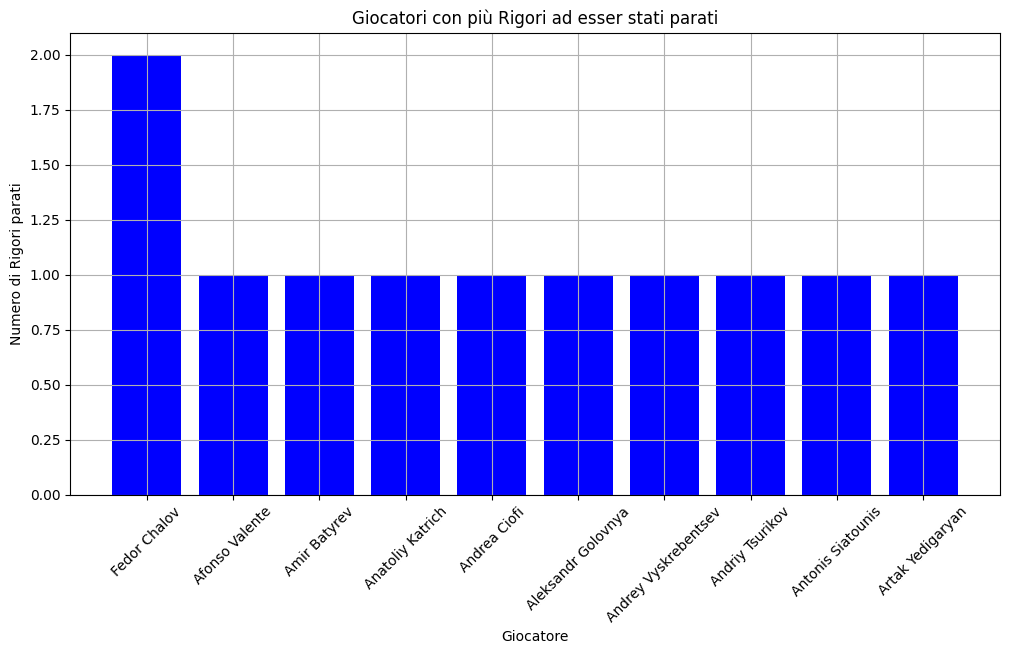

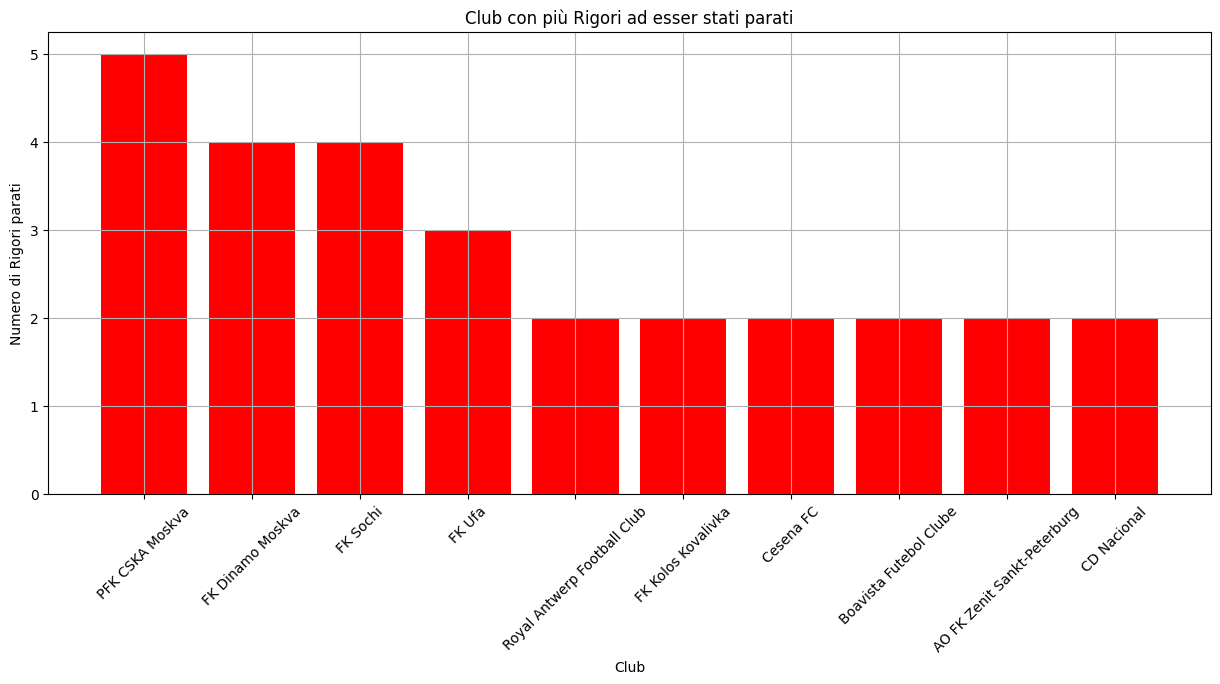

In [27]:
#adesso vado ad analizzare qual è il calciatore e il club con più rigori parati

saved_shootout = df_shootouts[df_shootouts['description'] == ', Saved']
player_shootout = pd.merge(saved_shootout, player_df, how='left', on='player_id')
player_shootout.rename(columns={'name': 'player_name'}, inplace=True)

shootout_by_player = player_shootout.groupby('player_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i giocatori
plt.figure(figsize=(12, 6))
plt.bar(shootout_by_player['player_name'], shootout_by_player['num_shootout'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Numero di Rigori parati')
plt.title('Giocatori con più Rigori ad esser stati parati')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

club_shootout = pd.merge(saved_shootout, club_df, how='left', on='club_id')
club_shootout.rename(columns={'name': 'club_name'}, inplace=True)

shootout_by_club = club_shootout.groupby('club_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i club
plt.figure(figsize=(15, 6))
plt.bar(shootout_by_club['club_name'], shootout_by_club['num_shootout'], color='red')
plt.xlabel('Club')
plt.ylabel('Numero di Rigori parati')
plt.title('Club con più Rigori ad esser stati parati')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

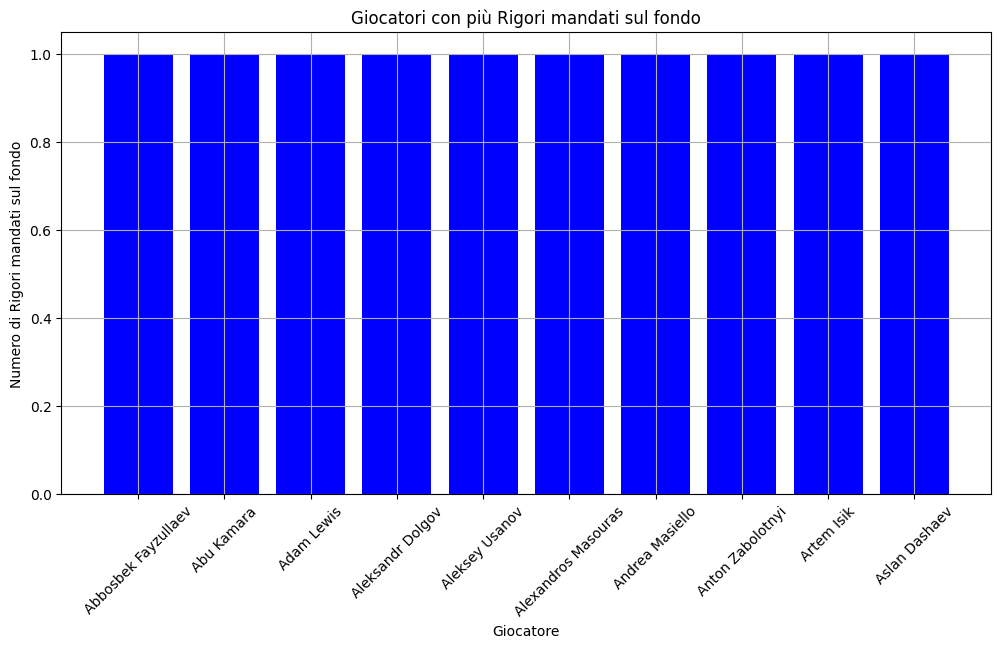

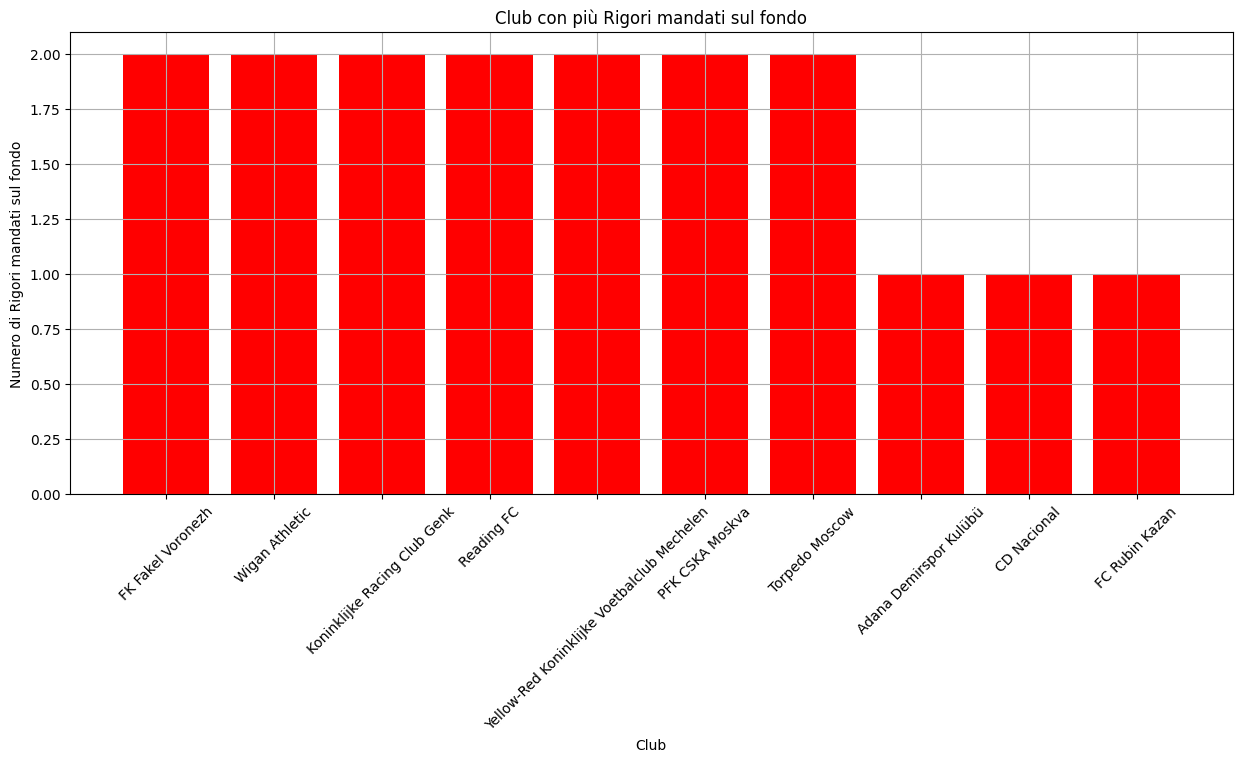

In [28]:
#adesso vado ad analizzare qual è il calciatore e il club con più rigori mandati sul fondo

missed_shootout = df_shootouts[df_shootouts['description'] == ', Missed']
player_shootout = pd.merge(missed_shootout, player_df, how='left', on='player_id')
player_shootout.rename(columns={'name': 'player_name'}, inplace=True)

shootout_by_player = player_shootout.groupby('player_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i giocatori
plt.figure(figsize=(12, 6))
plt.bar(shootout_by_player['player_name'], shootout_by_player['num_shootout'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Numero di Rigori mandati sul fondo')
plt.title('Giocatori con più Rigori mandati sul fondo')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

club_shootout = pd.merge(missed_shootout, club_df, how='left', on='club_id')
club_shootout.rename(columns={'name': 'club_name'}, inplace=True)

shootout_by_club = club_shootout.groupby('club_name').size().reset_index(name='num_shootout').sort_values(by='num_shootout', ascending=False).head(10)

#grafico per i giocatori
plt.figure(figsize=(15, 6))
plt.bar(shootout_by_club['club_name'], shootout_by_club['num_shootout'], color='red')
plt.xlabel('Club')
plt.ylabel('Numero di Rigori mandati sul fondo')
plt.title('Club con più Rigori mandati sul fondo')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [31]:
df_shootouts.columns

Index(['date', 'game_id', 'minute', 'type', 'club_id', 'player_id',
       'description'],
      dtype='object')

In [74]:
#adesso metto in relazione i rigori e il piede del calciatore
player_foot= pd.read_csv('players.csv')[['player_id','name','foot', 'position']] #devo rileggere da csv perché player_df non ha il dato foot

player_foot=pd.merge(player_foot,df_shootouts, on='player_id', how='inner')
player_foot

,player_id,name,foot,position,date,game_id,minute,type,club_id,description
0,8187,Juanmi Callejón,right,Attack,2023-11-01,4204047,-1,Shootout,4054,", Scored"
1,18922,Karim Benzema,right,Attack,2023-01-11,3998376,-1,Shootout,418,", Scored"
2,58418,Vadym Milko,right,Midfield,2023-08-23,4161649,-1,Shootout,48332,", Scored"
3,61561,Barry Bannan,left,Midfield,2023-08-08,4097135,-1,Shootout,1035,", Scored"
4,61561,Barry Bannan,left,Midfield,2023-08-29,4164100,-1,Shootout,1035,", Scored"
...,...,...,...,...,...,...,...,...,...,...
607,380761,Artem Makarchuk,left,Defender,2023-09-20,4126957,-1,Shootout,41231,", Saved"
608,91845,Heung-min Son,both,Attack,2023-08-29,4164109,-1,Shootout,148,", Scored"
609,293308,Christian Kudsk,left,Midfield,2023-09-28,4180935,-1,Shootout,12275,", Scored"
610,951293,Amir Batyrev,right,Midfield,2023-08-30,4126950,-1,Shootout,41231,", Scored"


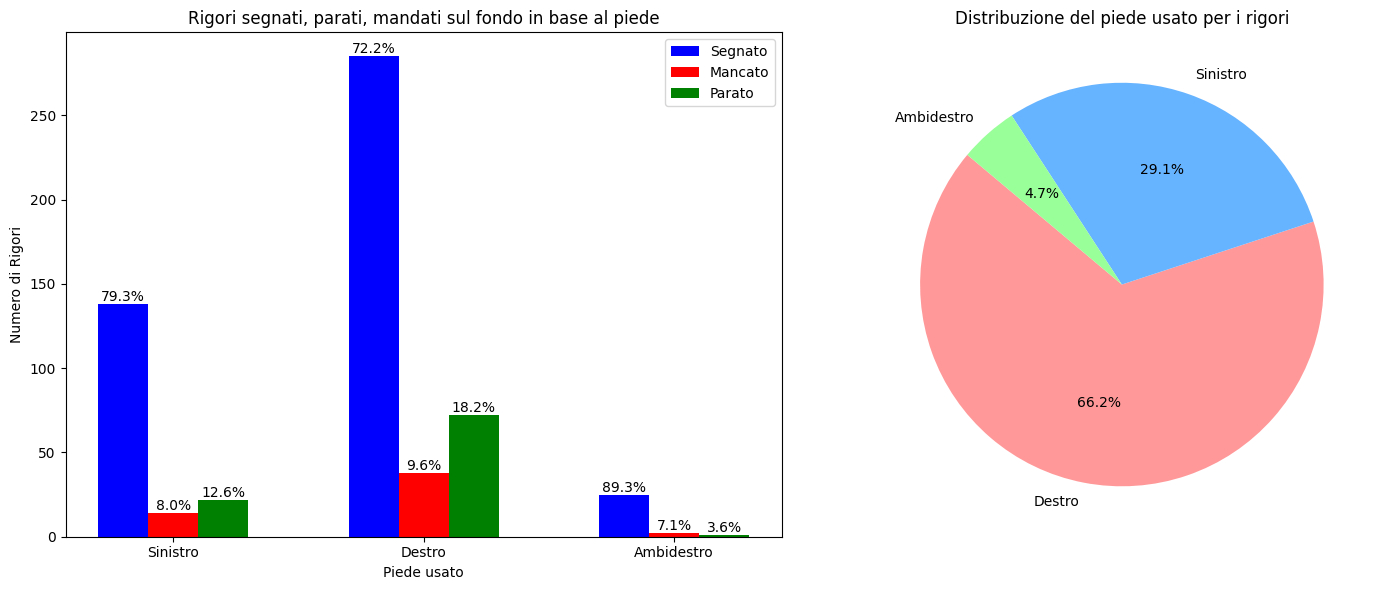

In [75]:
#Ora rappresento le percentuali di rigori segnati, parati e andati sul fondo in base al piede del calciatore, destro, sinistro
#o ambidestro.
#Osservando le percentuali possiamo vedere che gli ambidestri sono i più bravi a fare rigori, nonostante il numero sia inferiore (poichè ci sono
#meno giocatori ambidestri/mancini) la percentuale di successo è più alta

counts = player_foot.groupby(['foot', 'description']).size().unstack(fill_value=0)

counts = counts.reindex(['left', 'right', 'both']).fillna(0)

totals = counts.sum(axis=1)

percentages = counts.div(totals, axis=0) * 100

foot_totals = player_foot['foot'].value_counts(normalize=True) * 10

foot_labels = {
    'left': 'Sinistro',
    'right': 'Destro',
    'both': 'Ambidestro'
}

foot_totals.rename(index=foot_labels, inplace=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

bar_width = 0.2
index = range(len(counts))

positions_scored = [i - bar_width for i in index]
positions_missed = [i for i in index]
positions_saved = [i + bar_width for i in index]

bar_scored = ax1.bar(positions_scored, counts[', Scored'], bar_width, label='Segnato', color='b')
bar_missed = ax1.bar(positions_missed, counts[', Missed'], bar_width, label='Mancato', color='r')
bar_saved = ax1.bar(positions_saved, counts[', Saved'], bar_width, label='Parato', color='g')

for i in index:
    ax1.text(positions_scored[i], counts[', Scored'].iloc[i] + 0.05, f'{percentages[", Scored"].iloc[i]:.1f}%', ha='center', va='bottom')
    ax1.text(positions_missed[i], counts[', Missed'].iloc[i] + 0.05, f'{percentages[", Missed"].iloc[i]:.1f}%', ha='center', va='bottom')
    ax1.text(positions_saved[i], counts[', Saved'].iloc[i] + 0.05, f'{percentages[", Saved"].iloc[i]:.1f}%', ha='center', va='bottom')

ax1.set_xlabel('Piede usato')
ax1.set_ylabel('Numero di Rigori')
ax1.set_title('Rigori segnati, parati, mandati sul fondo in base al piede')
ax1.set_xticks(index)
ax1.set_xticklabels(['Sinistro', 'Destro', 'Ambidestro'])
ax1.legend()

ax2.pie(foot_totals, labels=foot_totals.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])

ax2.set_title('Distribuzione del piede usato per i rigori')

plt.tight_layout()
plt.show()

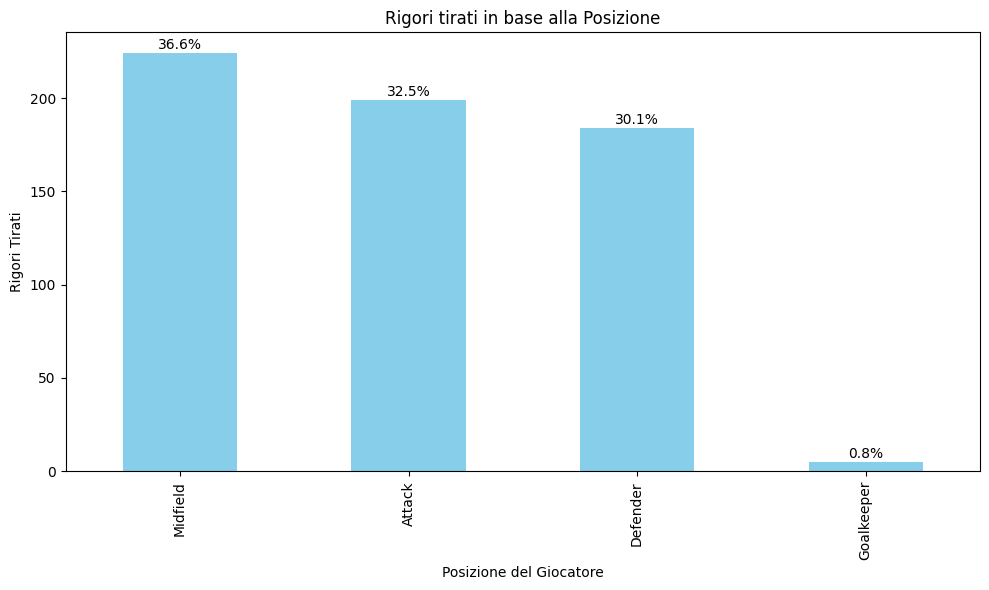

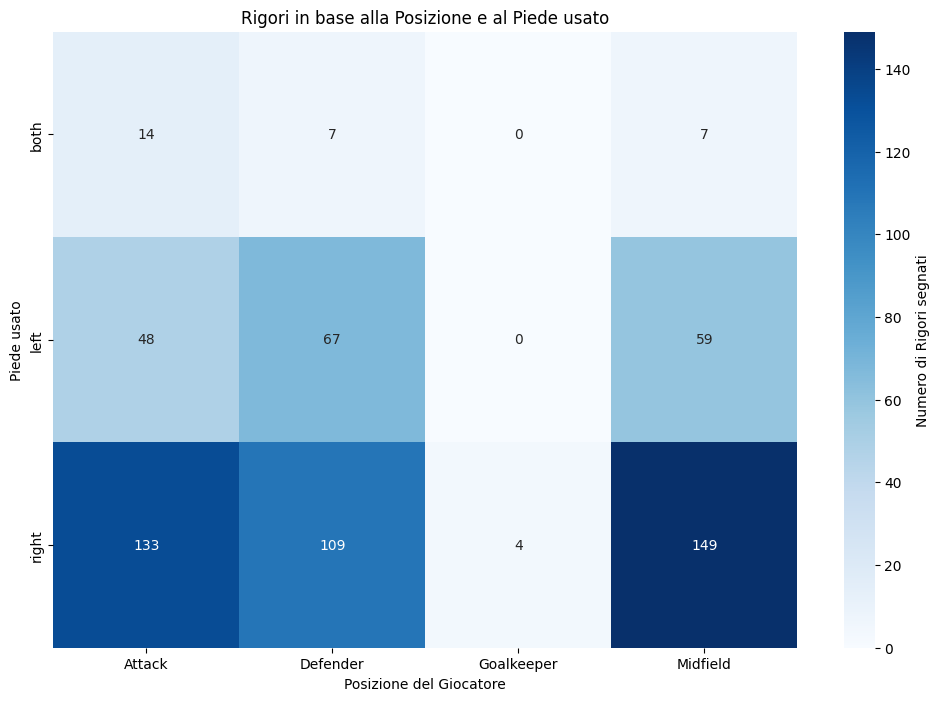

In [93]:
#ora voglio mettere in relazione i rigori e la posizione che ricopre un giocatore nella squadra così da poter 
#vedere quale ruolo di un giocatore si tende a far tirare di più i rigori.

scored_data = player_foot

penalties_count = scored_data['position'].value_counts()

total_penalties = penalties_count.sum()
percentages = (penalties_count / total_penalties) * 100

plt.figure(figsize=(10, 6))
bars = penalties_count.plot(kind='bar', color='skyblue')

for bar, percentage in zip(bars.patches, percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f'{percentage:.1f}%', 
             ha='center', va='bottom', fontsize=10, color='black')

plt.xlabel('Posizione del Giocatore')
plt.ylabel('Rigori Tirati')
plt.title('Rigori tirati in base alla Posizione')

plt.tight_layout()
plt.show()

#da quello che posso evincere dall'istogramma il ruolo a cui si predilige far tirare un rigore è il centro-campista, quasi 37%.
#ora aggiungo alla relazione di prima anche il piede utilizzato dal calciatore così da poter vedere anche la differza tra destri, mancini e ambidestri

pivot_table = scored_data.pivot_table(index='foot', columns='position', aggfunc='size', fill_value=0)

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt="d", cmap="Blues", cbar_kws={'label': 'Numero di Rigori segnati'})

plt.xlabel('Posizione del Giocatore')
plt.ylabel('Piede usato')
plt.title('Rigori in base alla Posizione e al Piede usato')
plt.show()

#in base a questa tabella posso dedurre che la predilizione va ai centro-campisti destri, per i mancini si predilige far tirare i difensori,
#mentre per gli attaccanti si prediligono gli ambidestri.

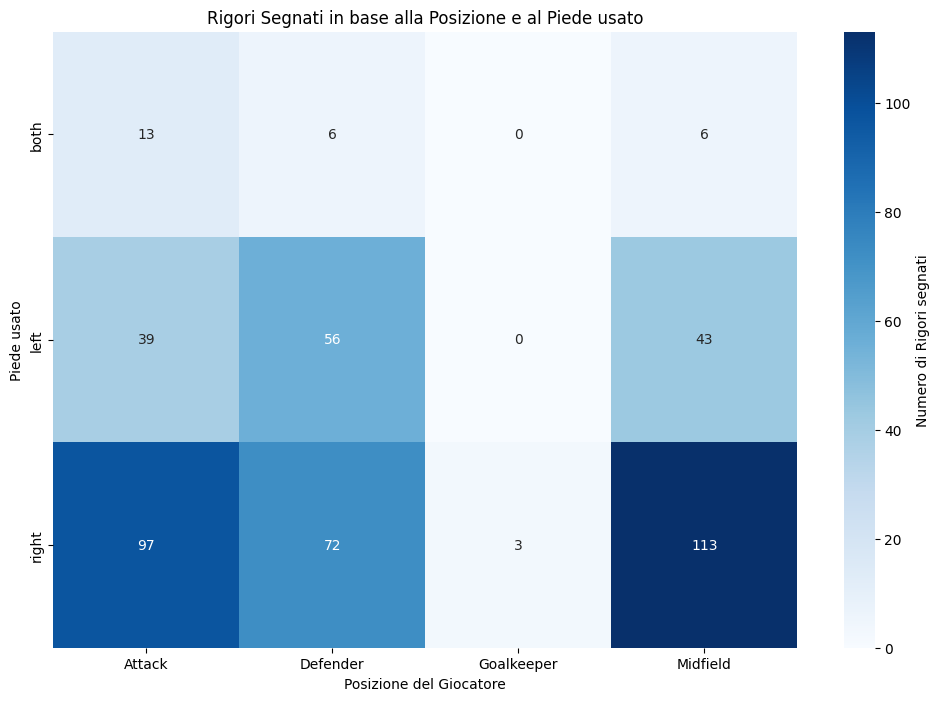

In [94]:
#quest'ultima deduzione da me fatta trova riscontro in questa tabella, dove al posto dei semplici rigori ho analizzato
#i rigori segnati.

scored_data = player_foot[player_foot['description'] == ', Scored']

pivot_table = scored_data.pivot_table(index='foot', columns='position', aggfunc='size', fill_value=0)

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt="d", cmap="Blues", cbar_kws={'label': 'Numero di Rigori segnati'})

plt.xlabel('Posizione del Giocatore')
plt.ylabel('Piede usato')
plt.title('Rigori Segnati in base alla Posizione e al Piede usato')
plt.show()

#da quel che si evince dalla tabella, a segnare più rigori sono i centro-campisti destri, mentre per il piede sinistro come prima sono i difensori
#e per concludere per gli ambidestri sono gli attaccanti a segnare più rigori.